<a href="https://colab.research.google.com/github/ludago4499/RecocidoAcero_/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import pandas as pd
from pylab import *
%pylab inline
import matplotlib.pyplot as plt
import collections
import os

Populating the interactive namespace from numpy and matplotlib


/usr/local/lib/python3.12/dist-packages/IPython/core/magics/pylab.py:159: UserWarning: pylab import has clobbered these variables: ['matmul', 'max', 'cross', 'random', 'bool', 'matrix_transpose', 'outer', 'vecdot', 'min', 'power', 'abs', 'trace', 'tensordot', 'round', 'diagonal', 'fft', 'pow']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


In [ ]:
from google.colab import drive
drive.mount('/content/drive/')
path = '/content/drive/MyDrive/Colab Notebooks/PCA Recocido/'
os.listdir(path)

Mounted at /content/drive/


['Recocido -Tec.xlsx', 'PCA.ipynb']

In [ ]:

df = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/PCA Recocido/Recocido -Tec.xlsx', header=1)
df.head(10)

In [ ]:
df_sorted = df.sort_values(by=['RH- Fecha Produccion', 'RH- Horno'])
df_sorted.head(30)

In [ ]:
#Useful with temperature
df_useful = df_sorted[df_sorted['RH- Temperatura Saturacion'] != 0]
df_useful.head(30)

In [ ]:
len(df_useful)

2708

In [ ]:
df_useful_sorted = df_useful.sort_values(by=['RH- Fecha Produccion', 'RH- Horno'])
df_useful_sorted.head(30)

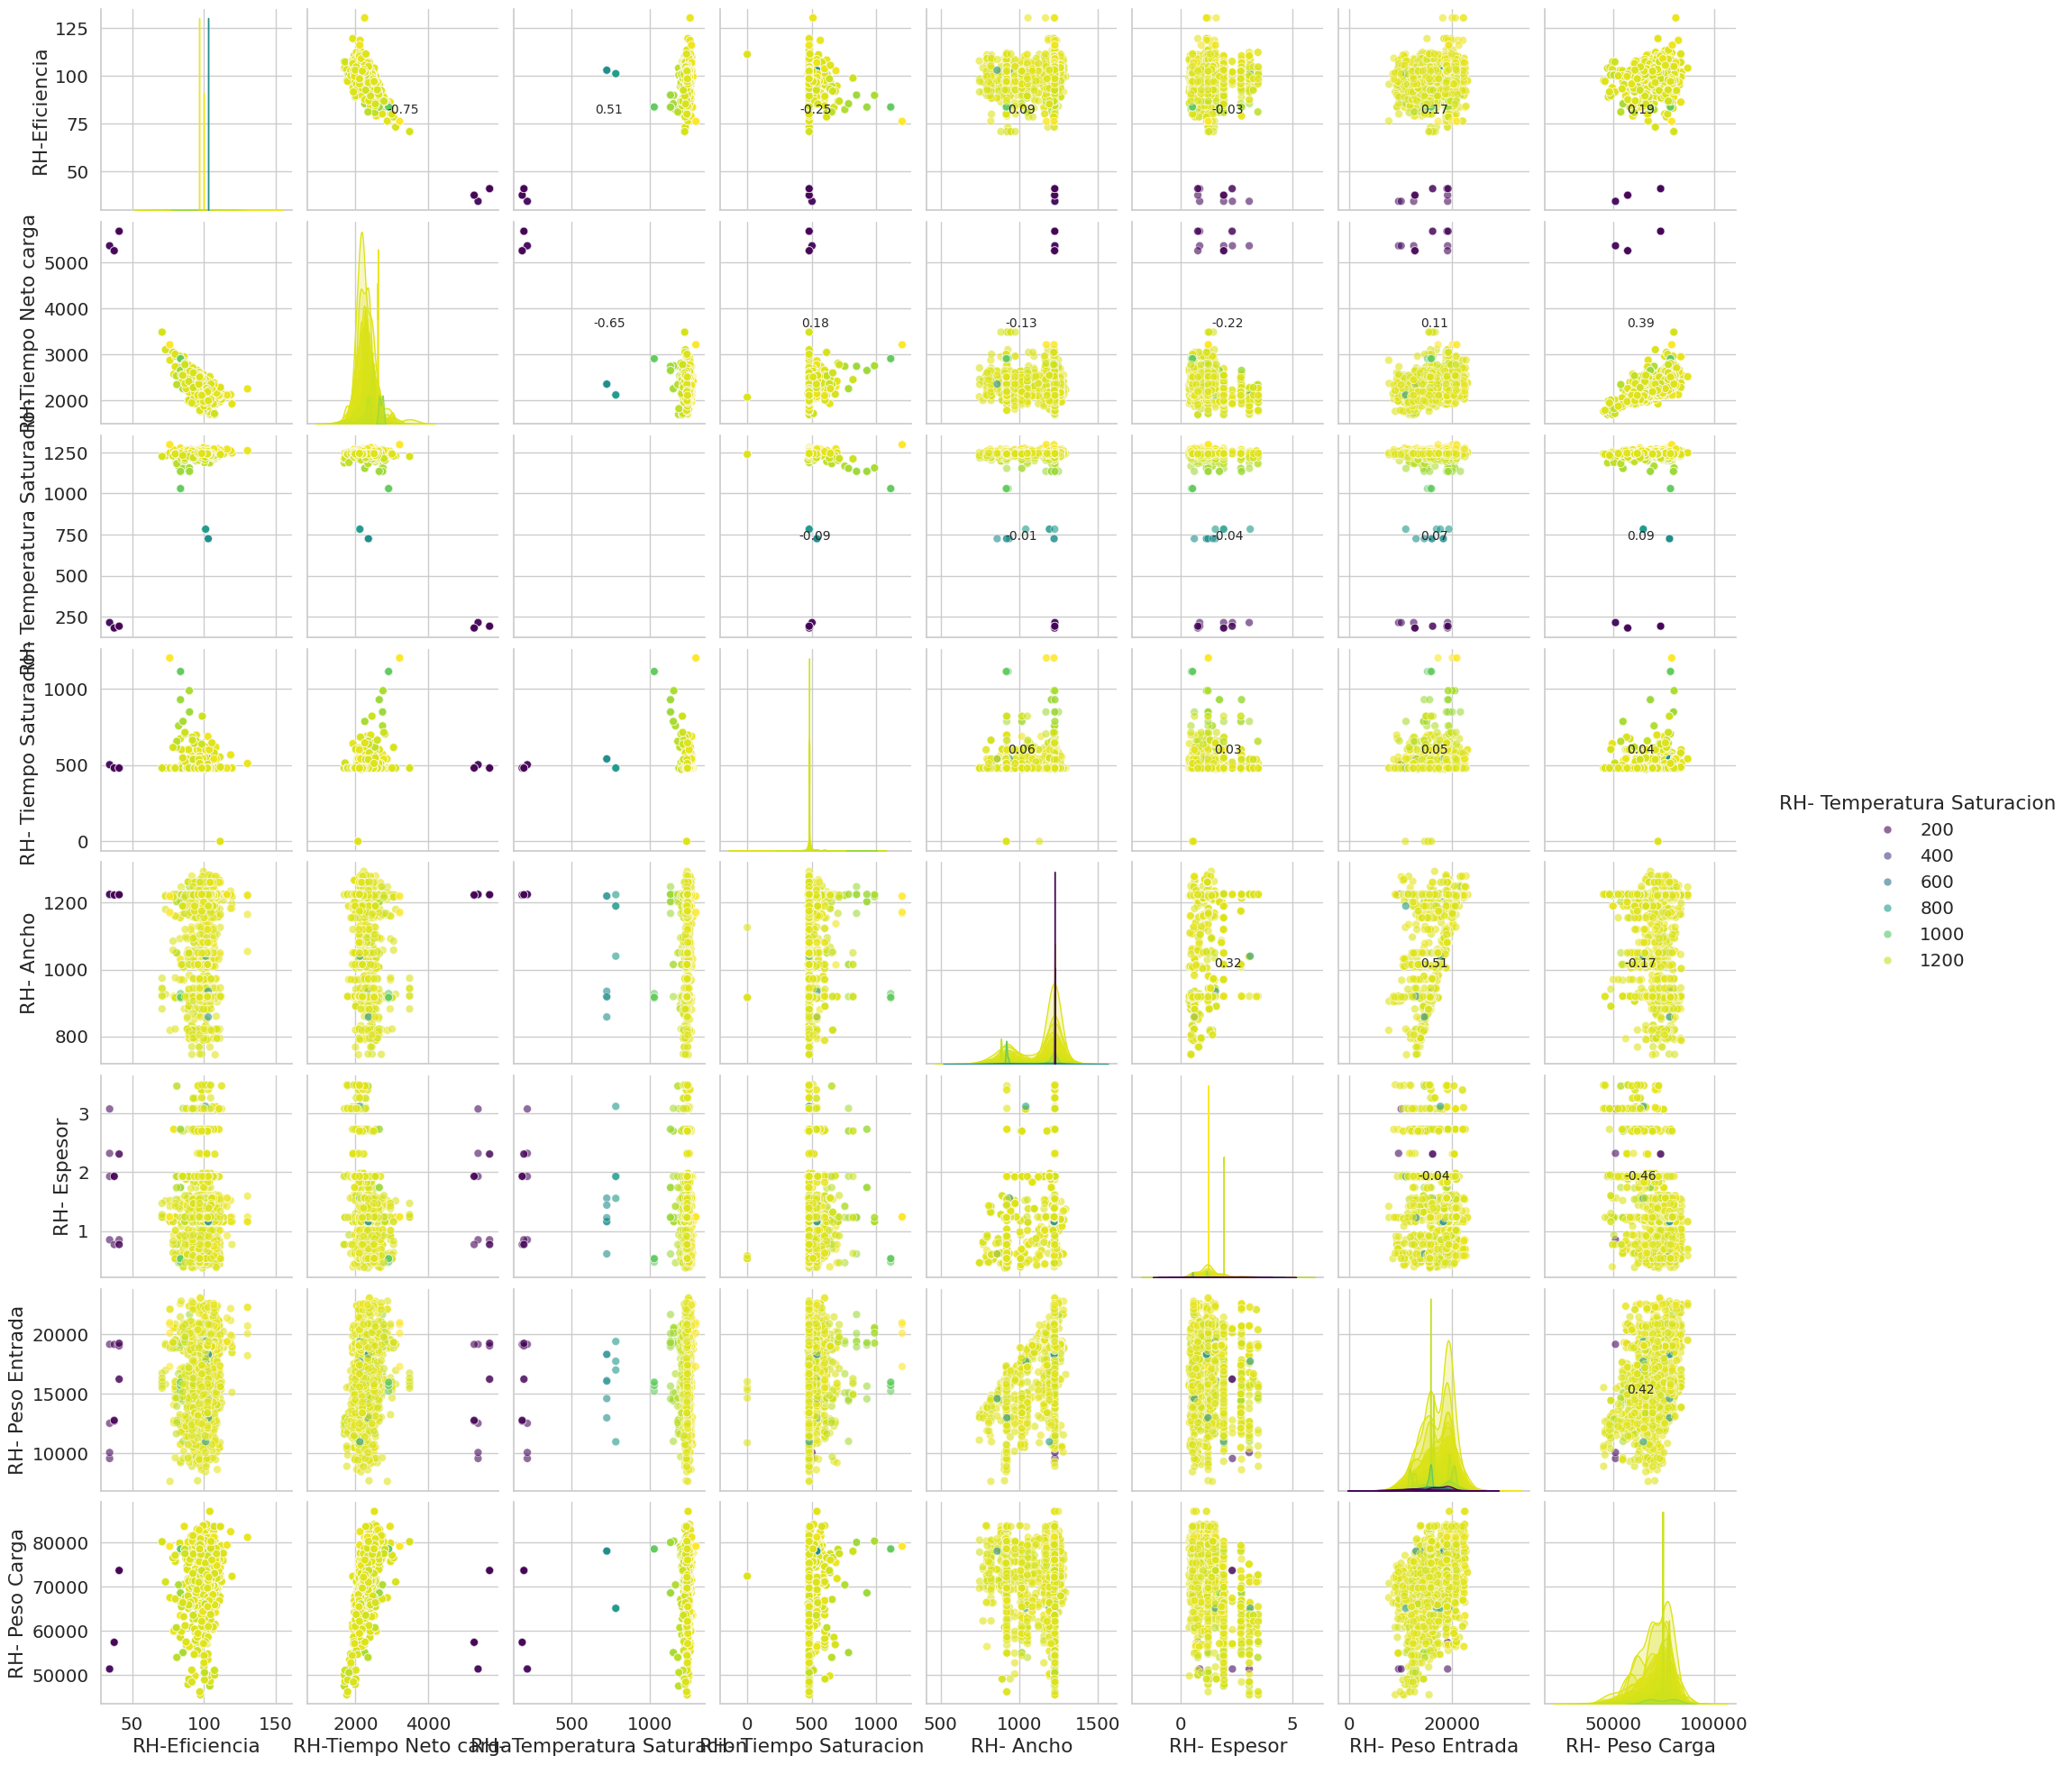

In [ ]:
import seaborn as sns

columns_to_plot = ['RH-Eficiencia', 'RH-Tiempo Neto carga', 'RH- Temperatura Saturacion', 'RH- Tiempo Saturacion ', 'RH- Ancho', 'RH- Espesor', 'RH- Peso Entrada','RH- Peso Carga']

#columns_to_plot = ["RH- Temperatura Saturacion", "RH-Eficiencia","RH- Peso Entrada", "RH- Largo"]

# plot
sns.set(style="whitegrid", font_scale=1.3)

pair_plot = sns.pairplot(
    df_useful,
    vars=columns_to_plot,
    hue="RH- Temperatura Saturacion",
    palette="viridis",
    diag_kind="kde",        # densidad en la diagonal
    plot_kws={"alpha": 0.6, "s": 40}
)

# Agregar correlaciones en la parte superior
for i, j in zip(*np.triu_indices_from(pair_plot.axes, 1)):
    col1 = columns_to_plot[j]
    col2 = columns_to_plot[i]
    corr = df_useful[col1].corr(df_useful[col2])
    pair_plot.axes[i, j].annotate(f"{corr:.2f}", (0.5, 0.5),
                                  xycoords='axes fraction', ha='center', va='center', fontsize=10)

plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

columns_to_use = ['RH-Eficiencia', 'RH-Tiempo Neto carga', 'RH- Temperatura Saturacion', 'RH- Tiempo Saturacion ', 'RH- Ancho', 'RH- Espesor', 'RH- Peso Entrada','RH- Peso Carga']

X = df_useful[columns_to_use]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Definir PCA, para 2 componentes
pca = PCA(n_components=2)

# Ajustar y transformar los datos
X_pca = pca.fit_transform(X_scaled)

# Convertir a DataFrame para facilidad
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["RH-Eficiencia"] = df_useful["RH-Eficiencia"]  # para colorear

In [ ]:
print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza total explicada por los 2 componentes:", sum(pca.explained_variance_ratio_))

Varianza explicada por cada componente: [0.29864182 0.22421092]
Varianza total explicada por los 2 componentes: 0.5228527321116316


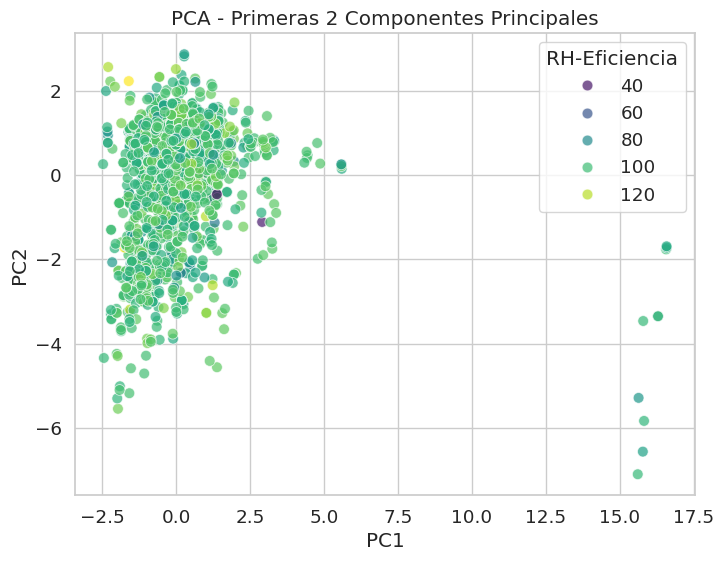

In [ ]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8,6))

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="RH-Eficiencia", palette="viridis", s=60, alpha=0.7)
plt.title("PCA - Primeras 2 Componentes Principales")
plt.show()

In [ ]:
column_headers = df_useful.columns.tolist()
print(column_headers)

['Material', 'TDM- Ancho Entrada', 'TDM- Espesor Entrada', 'TDM- Peso de Salida', 'TDM- Ancho de Salida', 'TDM- Espesor Salida', 'RH- Fecha Produccion', 'RH-Eficiencia', 'RH-Tiempo Neto carga', 'RH-Tiempo STD Carga', 'RH- Ancho', 'RH- Espesor', 'RH- Peso Entrada', 'RH-Familia acero', 'RH-Acero', 'RH- Base', 'RH- Carga', 'RH- Enfriador', 'RH- Horno', 'RH- Peso Carga', 'RH- Posicion', 'RH- Práctica', 'RH- Temperatura Saturacion', 'RH- Tiempo Saturacion ', 'RH- Peso de Salida', 'RH- Ancho de Salida', 'RH- Espesor Salida', 'RH- Largo', 'Fecha Temple', 'Elongación Temple', 'LAB_CHU_PM - Fecha Creacion', 'LAB_CHU_PM - ID Muestra NCA', 'LAB_CHU_PM - Material Muestreado', 'Tensión L - Elongación', 'Tensión L - Ancho probeta', 'Tensión L - Espesor probeta', 'Tensión L - Orientación', 'Tensión L - Punto de cedencia', 'Tensión L - Resistencia']
